## Regresion Lineal: implementado desde cero en Python

### Importar paquetes y cargar dataset

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(100)

data = pd.read_csv('../data/dataset.csv')
data

,Area,Precio
0,152.272727,65928.860150
1,102.272727,44477.418490
2,222.727273,95848.621980
3,79.545455,44964.898270
4,86.363636,34367.391220
...,...,...
95,250.000000,115005.373300
96,56.818182,8352.614705
97,43.181818,20876.532260
98,88.636364,39033.388430


In [12]:
data.shape

(100, 2)

### Obtener valores en x(area) e y(precio)

In [13]:
x1 = data['Area'].values
y = data['Precio'].values

Text(0, 0.5, 'y (Precio en U$)')

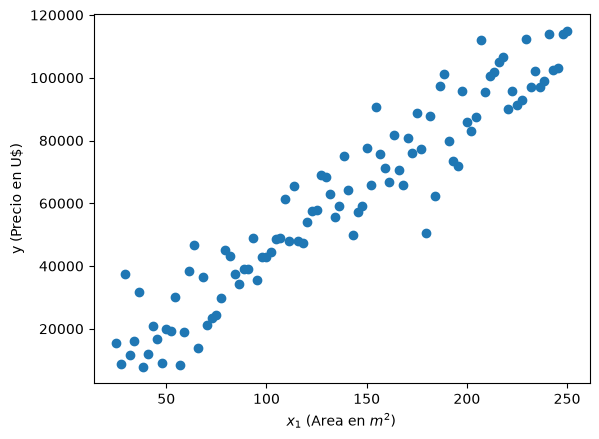

In [14]:
plt.scatter(x1, y)
plt.xlabel('$x_1$ (Area en $m^2$)')
plt.ylabel('y (Precio en U$)')

### Funcion para construir el modelo lineal

#### Perdida
$L(\omega, b)=\frac{1}{2m}\sum_{i=1}^m[w x_1^{(i)}+b-y^{(i)}]^2$

In [15]:
def calcular_perdida(x,y,w,b,m):
    errores_individuales = np.square([w*x+b-y])
    perdida = np.sum(errores_individuales)/(2*m)

    return perdida


#### Gradiende Descendiente

Los parámetros (coeficientes) se actualizan así:

$\omega \leftarrow \omega - \alpha \frac{\partial L(\omega ,b)}{\partial \omega}$

$b \leftarrow b - \alpha \frac{\partial L(\omega ,b)}{\partial b}$

donde las derivadas parciales son:

$\frac{\partial L(\omega ,b)}{\partial \omega} = \frac{1}{m} \sum_{i=1}^m x_1^{(i)} [w \cdot x_1^{(i)} + b - y^{(i)}]$

$\frac{\partial L(\omega ,b)}{\partial b} = \frac{1}{m} \sum_{i=1}^m [w \cdot x_1^{(i)} + b - y^{(i)}]$

In [16]:
def gradiente_descendiente(w,b,alpha,x,y,m):
    # dL_w y dL_b
    dL_w = np.sum(x*(w*x+b-y))/m
    dL_b = np.sum(w*x+b-y)/m
    # actualizacion de pesos
    w = w - alpha*dL_w
    b = b - alpha*dL_b

    return w,b

#### Prediccion con el modelo ya entrenado

$\hat{y} = w \cdot x_1 +b$

In [17]:
def predecir(x,w,b):
    y_pred = w*x + b

    return y_pred

#### Entrenamiento

In [18]:
# modificar estos hiper-parametros para observar diferentes comportamientos
nits = 20  # nuemro de iteracion
alpha = 0.00001  # Tasa de aprendizaje

In [19]:
def entrenar(x,y,nits,alpha):
    m = x.shape[0] # numero de datos de entrenamiento
    # inicializar pesos (random.seed(100)) garantiza que siempre inicializa en los mismos valores
    w = np.random.rand()
    b = np.random.rand()
    # perdida inicial
    perdida = []
    perdida_i = calcular_perdida(x,y,w,b,m)
    perdida.append(perdida_i)
    # imprimir valores iniciales
    print('Inicializacion. '+ 'Loss: '+ str(perdida_i) + ', w: '+ str(w)+', b: '+str(b))
    # entrenamiento
    for it in range(nits):
        # aplicar gradiente descendiente
        w, b = gradiente_descendiente(w,b,alpha,x,y,m)
        # actualizar perdida
        perdida_it = calcular_perdida(x,y,w,b,m)
        perdida.append(perdida_it)
        # imprimir en pantalla
        print('Iteracion: '+ str(it) +'. '+'Loss: '+ str(perdida_it)+ ', w: '+ str(w)+', b: '+str(b))

    return w, b, perdida

#### Ejecutar entrenamiento

In [20]:
w, b, perdida = entrenar(x1, y, nits, alpha)

Inicializacion. Loss: 2342513281.6845264, w: 0.5434049417909654, b: 0.27836938509379616
Iteracion: 0. Loss: 1399076234.1410716, w: 103.8519481105296, b: 0.8917790839922826
Iteracion: 1. Loss: 842774418.932353, w: 183.1815001792977, b: 1.3631334019367647
Iteracion: 2. Loss: 514748600.5259574, w: 244.09783480626044, b: 1.725404872243511
Iteracion: 3. Loss: 321326730.20723486, w: 290.8748515968026, b: 2.0039127597234803
Iteracion: 4. Loss: 207274671.40872478, w: 326.7944335305008, b: 2.2180994640375795
Iteracion: 5. Loss: 140023371.95087615, w: 354.3767043552464, b: 2.3828946013258006
Iteracion: 6. Loss: 100368346.60418291, w: 375.5568408412684, b: 2.5097624682786237
Iteracion: 7. Loss: 76985585.9717157, w: 391.8208450688884, b: 2.607506378884497
Iteracion: 8. Loss: 63197837.979843065, w: 404.3098025537505, b: 2.6828863062382866
Iteracion: 9. Loss: 55067831.500292644, w: 413.89994097497845, b: 2.7410931632511173
Iteracion: 10. Loss: 50273937.25105092, w: 421.2641064384394, b: 2.7861129978

#### Dibujar el comportamiento del error

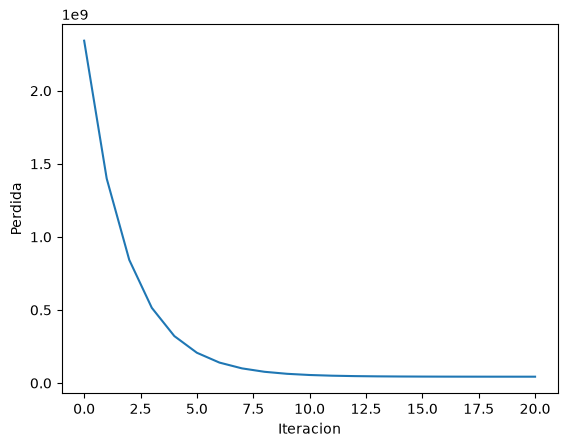

In [21]:
plt.plot(perdida)
plt.xlabel('Iteracion')
plt.ylabel('Perdida')
plt.show()

#### Dibujar la recta resultante

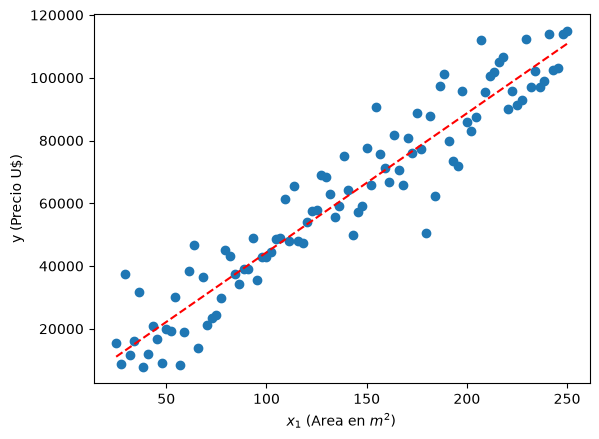

In [22]:
x_pred = np.linspace(x1.min(), x1.max(), x1.shape[0])
y_pred = predecir(x_pred, w, b)

plt.scatter(x1, y)
plt.plot(x_pred, y_pred, 'r--')
plt.xlabel('$x_1$ (Area en $m^2$)')
plt.ylabel('y (Precio U$)')
plt.show()